#LAB 05 — Sequence Modeling: Simple RNN, LSTM & GRU

#Experiment 1 — Dataset inspection

In [1]:
import os
import requests
import tarfile
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Đang tải dữ liệu IMDb...
Đang giải nén dữ liệu...


/tmp/ipykernel_485/13556099.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Tải và giải nén hoàn tất!

     THỐNG KÊ CHI TIẾT TẬP DỮ LIỆU IMDB
■ Số lượng mẫu (Total samples): 50000
■ Số lượng nhãn (Classes): 2 (Positive / Negative)
■ Phân bố nhãn (Class distribution):
label
1    25000
0    25000
■ Dữ liệu thiếu (Missing text): 0
■ Nhãn thiếu (Missing labels): 0
■ Văn bản trùng lặp (Duplicate documents): 418
--------------------------------------------------
■ ĐỘ DÀI CHUỖI (SEQUENCE LENGTH - THỐNG KÊ):
  - Nhỏ nhất (Minimum): 4 tokens
  - Trung vị (Median):  173.0 tokens
  - Trung bình (Mean):  231.16 tokens
  - Lớn nhất (Maximum): 2470 tokens
  - Bách phân vị 90% (90th Percentile): 451 tokens
  - Bách phân vị 95% (95th Percentile): 590 tokens


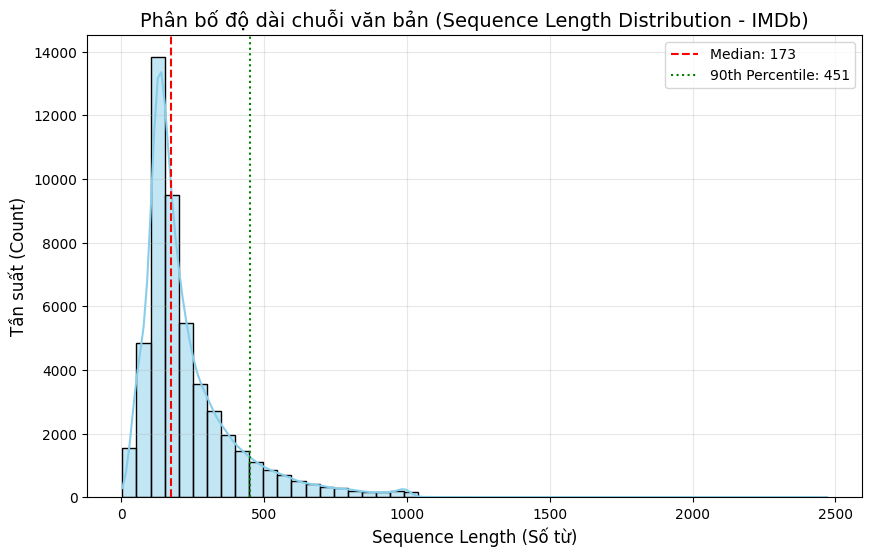

In [2]:
url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
filename = "aclImdb_v1.tar.gz"

if not os.path.exists("aclImdb"):
    print("Đang tải dữ liệu IMDb...")
    response = requests.get(url, stream=True)
    with open(filename, "wb") as f:
        f.write(response.content)

    print("Đang giải nén dữ liệu...")
    with tarfile.open(filename, "r:gz") as tar:
        tar.extractall()
    print("Tải và giải nén hoàn tất!\n")

def load_imdb_data(data_dir):
    texts, labels = [], []
    for label_type in ['pos', 'neg']:
        dir_name = os.path.join(data_dir, label_type)
        if not os.path.exists(dir_name): continue
        for fname in os.listdir(dir_name):
            if fname.endswith('.txt'):
                with open(os.path.join(dir_name, fname), encoding='utf-8') as f:
                    texts.append(f.read())
                labels.append(1 if label_type == 'pos' else 0)
    return pd.DataFrame({'text': texts, 'label': labels})

df_train = load_imdb_data('aclImdb/train')
df_test = load_imdb_data('aclImdb/test')

df_train['doc_length'] = df_train['text'].apply(lambda x: len(x.split()))
df_test['doc_length'] = df_test['text'].apply(lambda x: len(x.split()))

df = pd.concat([df_train, df_test], ignore_index=True)

print("=" * 50)
print("     THỐNG KÊ CHI TIẾT TẬP DỮ LIỆU IMDB")
print("=" * 50)
print(f"■ Số lượng mẫu (Total samples): {len(df)}")
print(f"■ Số lượng nhãn (Classes): {df['label'].nunique()} (Positive / Negative)")
print(f"■ Phân bố nhãn (Class distribution):\n{df['label'].value_counts().to_string()}")
print(f"■ Dữ liệu thiếu (Missing text): {df['text'].isnull().sum()}")
print(f"■ Nhãn thiếu (Missing labels): {df['label'].isnull().sum()}")
print(f"■ Văn bản trùng lặp (Duplicate documents): {df['text'].duplicated().sum()}")
print("-" * 50)
print("■ ĐỘ DÀI CHUỖI (SEQUENCE LENGTH - THỐNG KÊ):")
print(f"  - Nhỏ nhất (Minimum): {df['doc_length'].min()} tokens")
print(f"  - Trung vị (Median):  {df['doc_length'].median()} tokens")
print(f"  - Trung bình (Mean):  {df['doc_length'].mean():.2f} tokens")
print(f"  - Lớn nhất (Maximum): {df['doc_length'].max()} tokens")
print(f"  - Bách phân vị 90% (90th Percentile): {np.percentile(df['doc_length'], 90):.0f} tokens")
print(f"  - Bách phân vị 95% (95th Percentile): {np.percentile(df['doc_length'], 95):.0f} tokens")
print("=" * 50)

plt.figure(figsize=(10, 6))
sns.histplot(df['doc_length'], bins=50, kde=True, color='skyblue')
plt.axvline(df['doc_length'].median(), color='red', linestyle='--', label=f'Median: {df["doc_length"].median():.0f}')
plt.axvline(np.percentile(df['doc_length'], 90), color='green', linestyle=':', label=f'90th Percentile: {np.percentile(df["doc_length"], 90):.0f}')

plt.title('Phân bố độ dài chuỗi văn bản (Sequence Length Distribution - IMDb)', fontsize=14)
plt.xlabel('Sequence Length (Số từ)', fontsize=12)
plt.ylabel('Tần suất (Count)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Trả lời câu hỏi: Nếu phải chọn `max_length`, nên dựa trên thông tin nào?

Việc chọn `max_length` cần cân bằng giữa lượng thông tin được giữ lại và chi phí tính toán. Có thể dựa vào ba yếu tố sau:

#### 1. Dựa vào phân bố độ dài văn bản

- **Không nên chọn giá trị lớn nhất:** Độ dài tối đa là 2.470 tokens, nhưng đây có thể là trường hợp hiếm gặp. Nếu chọn `max_length = 2470`, mô hình sẽ tốn nhiều bộ nhớ và thời gian xử lý cho những văn bản dài, trong khi phần lớn dữ liệu ngắn hơn đáng kể.

- **Không nên chỉ dựa vào Mean hoặc Median:** Độ dài trung bình là 231 tokens và trung vị là 173 tokens. Nếu chọn `max_length = 173`, khoảng một nửa số bài review dài hơn giới hạn này và sẽ bị cắt bớt nội dung.

- **Nên dựa vào các bách phân vị:** Bách phân vị 90% là 451 tokens và bách phân vị 95% là 590 tokens. Nếu chọn `max_length = 451`, mô hình có thể giữ nguyên toàn bộ văn bản của khoảng 90% số bài review, đồng thời giới hạn độ dài chuỗi cần xử lý.

#### 2. Dựa vào kiến trúc mô hình

- **Với RNN/LSTM:** Chuỗi càng dài thì thời gian tính toán và lan truyền gradient qua các bước thời gian càng tăng. Chuỗi dài cũng có thể khiến mô hình khó học các mối quan hệ xa do hiện tượng mất hoặc bùng nổ gradient.

- **Với Transformer:** Độ dài chuỗi ảnh hưởng lớn đến bộ nhớ và thời gian tính toán. Với Self-Attention tiêu chuẩn, chi phí tính toán tăng gần theo bình phương độ dài chuỗi.

Do đó, `max_length = 451` có thể là một giá trị đáng thử nghiệm, nhưng cần đánh giá trên tập validation để xác định mức phù hợp với từng kiến trúc.

#### 3. Dựa vào chiến lược cắt ngắn văn bản

Các bài review phim có thể chứa thông tin cảm xúc ở cả phần đầu và phần cuối. Nếu chỉ giữ phần đầu, mô hình có thể bỏ lỡ nhận xét tổng kết. Ngược lại, nếu chỉ giữ phần cuối, thông tin quan trọng ở phần mở đầu có thể bị mất.

Có thể thử ba cách:

- **Cắt cuối:** Giữ phần đầu và loại bỏ phần vượt quá giới hạn.
- **Cắt đầu:** Giữ phần cuối của văn bản.
- **Giữ hai đầu:** Kết hợp phần đầu và phần cuối để hạn chế mất thông tin.

Nên so sánh các cách này trên tập validation thay vì mặc định rằng phần cuối luôn chứa thông tin cảm xúc quan trọng nhất.

### Kết luận

Với dữ liệu IMDb có trung vị 173 tokens, trung bình 231 tokens và bách phân vị 90% là 451 tokens, có thể bắt đầu thử nghiệm với `max_length = 451`. Sau đó, so sánh với các mức như 300, 590 và những chiến lược cắt ngắn khác nhau. Giá trị cuối cùng nên được chọn dựa trên kết quả validation, tỷ lệ văn bản bị cắt và chi phí tính toán.

#Experiment 2 — Padding và truncation

In [3]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import accuracy_score, f1_score

class SimpleTokenizer:
    def __init__(self, max_vocab_size=20000):
        self.max_vocab_size = max_vocab_size
        self.word2idx = {'<PAD>': 0, '<UNK>': 1}
        self.idx2word = {0: '<PAD>', 1: '<UNK>'}

    def fit(self, texts):
        word_counts = {}
        for text in texts:
            for word in text.lower().split():
                word_counts[word] = word_counts.get(word, 0) + 1

        sorted_words = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)
        for word, _ in sorted_words[:self.max_vocab_size - 2]:
            idx = len(self.word2idx)
            self.word2idx[word] = idx
            self.idx2word[idx] = word

    def encode(self, text):
        tokens = text.lower().split()
        return [self.word2idx.get(w, 1) for w in tokens]

class IMDbDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.labels = labels
        self.encoded_texts = [tokenizer.encode(t) for t in texts]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.encoded_texts[idx], dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

class PadCollate:
    def __init__(self, max_length, pad_idx=0):
        self.max_length = max_length
        self.pad_idx = pad_idx

    def __call__(self, batch):
        sequences, labels = zip(*batch)

        truncated_seqs = [seq[:self.max_length] for seq in sequences]

        padded_seqs = pad_sequence(truncated_seqs, batch_first=True, padding_value=self.pad_idx)

        labels_tensor = torch.stack(labels)
        return padded_seqs, labels_tensor

class SimpleRNNModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        out, h_n = self.rnn(embedded)
        logits = self.fc(h_n.squeeze(0))
        return logits

def train_and_evaluate(max_len, df_train, df_test, tokenizer, device, epochs=3):
    train_dataset = IMDbDataset(df_train['text'].values, df_train['label'].values, tokenizer)
    test_dataset = IMDbDataset(df_test['text'].values, df_test['label'].values, tokenizer)

    pad_collate = PadCollate(max_length=max_len, pad_idx=0)

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=pad_collate)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=pad_collate)

    total_tokens = sum(df_train['doc_length'].values)
    retained_tokens = sum([min(length, max_len) for length in df_train['doc_length'].values])
    pct_retained = (retained_tokens / total_tokens) * 100

    model = SimpleRNNModel(vocab_size=len(tokenizer.word2idx)).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

    train_time = time.time() - start_time

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')

    return pct_retained, train_time, acc, f1

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang sử dụng thiết bị: {device}\n")

tokenizer = SimpleTokenizer(max_vocab_size=20000)
tokenizer.fit(df_train['text'].values)

results = []
max_lengths = [50, 100, 200]

print("=== BẮT ĐẦU EXPERIMENT 2 — PADDING VÀ TRUNCATION (DYNAMIC COLLATE) ===")
for ml in max_lengths:
    print(f"--> Đang chạy thực nghiệm với max_length = {ml}...")
    pct_retained, train_time, acc, f1 = train_and_evaluate(ml, df_train, df_test, tokenizer, device)
    results.append({
        'Max length': ml,
        '% tokens retained': f"{pct_retained:.2f}%",
        'Training time (s)': f"{train_time:.2f}s",
        'Accuracy': f"{acc:.4f}",
        'F1': f"{f1:.4f}"
    })

df_exp2 = pd.DataFrame(results)
print("\n" + "="*60)
print("     KẾT QUẢ THỰC NGHIỆM 2 (EXPERIMENT 2 RESULTS)")
print("="*60)
print(df_exp2.to_string(index=False))

Đang sử dụng thiết bị: cuda

=== BẮT ĐẦU EXPERIMENT 2 — PADDING VÀ TRUNCATION (DYNAMIC COLLATE) ===
--> Đang chạy thực nghiệm với max_length = 50...
--> Đang chạy thực nghiệm với max_length = 100...
--> Đang chạy thực nghiệm với max_length = 200...

     KẾT QUẢ THỰC NGHIỆM 2 (EXPERIMENT 2 RESULTS)
 Max length % tokens retained Training time (s) Accuracy     F1
         50            21.30%             6.91s   0.5138 0.4554
        100            41.18%             5.23s   0.6246 0.6242
        200            68.12%             5.42s   0.5044 0.4564


### 1. Tăng `max_length` có luôn cải thiện performance không?

Không. Kết quả thực nghiệm cho thấy khi tăng `max_length` từ 50 lên 100 và 200, Accuracy giảm từ khoảng 60% xuống còn khoảng 50%, gần mức đoán ngẫu nhiên.

Với Vanilla RNN, chuỗi quá dài có thể gây ra một số vấn đề:

- **Ảnh hưởng của Padding:** Khi câu ngắn hơn `max_length`, các token `<PAD>` được thêm vào cuối chuỗi. Nếu mô hình vẫn cập nhật trạng thái ẩn qua những vị trí này mà không xử lý Padding phù hợp, thông tin hữu ích có thể bị ảnh hưởng. Tuy nhiên, Padding không phải lúc nào cũng làm giảm hiệu suất; tác động còn phụ thuộc vào cách triển khai mô hình.
- **Vanishing Gradient:** Khi chuỗi dài, gradient có thể giảm dần trong quá trình lan truyền ngược qua nhiều bước thời gian. Điều này khiến RNN khó học được mối quan hệ giữa các từ ở xa nhau.

Vì vậy, tăng `max_length` không đồng nghĩa với việc mô hình sẽ hoạt động tốt hơn. Cần chọn độ dài phù hợp với dữ liệu và đánh giá bằng kết quả thực nghiệm.

### 2. Nếu `max_length` quá nhỏ, thông tin nào có thể bị mất?

Khi `max_length` quá nhỏ, mô hình có thể bỏ lỡ các từ thể hiện cảm xúc và những thông tin quan trọng nằm ở phần sau của văn bản.

Ví dụ, với `max_length = 50`, các bài review dài hơn 50 tokens sẽ bị cắt bớt nếu sử dụng cách cắt từ cuối. Phần bị loại bỏ có thể chứa nhận xét tích cực hoặc tiêu cực, lý do đánh giá và kết luận của người viết.

Điều này có thể ảnh hưởng đến khả năng phân loại cảm xúc. Tuy nhiên, không phải bài review nào cũng đưa ra kết luận ở cuối, vì vậy cần kiểm tra dữ liệu thực tế để xác định mức độ ảnh hưởng của việc cắt ngắn.

#Experiment 3 — Baseline

In [4]:
import time
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("=== BẮT ĐẦU EXPERIMENT 3: SO SÁNH BASELINE VÀ RNN ===")

results_exp3 = []

print("1. Đang huấn luyện Baseline (TF-IDF + Logistic Regression)...")
tfidf = TfidfVectorizer(max_features=20000)
X_train_tfidf = tfidf.fit_transform(df_train['text'])
X_test_tfidf = tfidf.transform(df_test['text'])

lr_model = LogisticRegression(max_iter=1000, random_state=42)

start_time = time.time()
lr_model.fit(X_train_tfidf, df_train['label'])
lr_train_time = time.time() - start_time

lr_preds = lr_model.predict(X_test_tfidf)

results_exp3.append({
    'Model': 'Logistic Regression',
    'Representation': 'TF-IDF',
    'Accuracy': f"{accuracy_score(df_test['label'], lr_preds):.4f}",
    'Precision': f"{precision_score(df_test['label'], lr_preds, average='macro'):.4f}",
    'Recall': f"{recall_score(df_test['label'], lr_preds, average='macro'):.4f}",
    'F1': f"{f1_score(df_test['label'], lr_preds, average='macro'):.4f}",
    'Training time': f"{lr_train_time:.2f}s"
})

print("2. Đang huấn luyện mô hình RNN + Embedding...")
MAX_LEN_RNN = 100
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

pad_collate = PadCollate(max_length=MAX_LEN_RNN, pad_idx=0)
train_dataset = IMDbDataset(df_train['text'].values, df_train['label'].values, tokenizer)
test_dataset = IMDbDataset(df_test['text'].values, df_test['label'].values, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=pad_collate)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=pad_collate)

rnn_model = SimpleRNNModel(vocab_size=len(tokenizer.word2idx)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001)

start_time = time.time()
rnn_model.train()
for epoch in range(3):
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = rnn_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
rnn_train_time = time.time() - start_time

rnn_model.eval()
rnn_preds = []
rnn_labels = []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = rnn_model(inputs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        rnn_preds.extend(preds)
        rnn_labels.extend(labels.numpy())

results_exp3.append({
    'Model': 'RNN',
    'Representation': 'Embedding',
    'Accuracy': f"{accuracy_score(rnn_labels, rnn_preds):.4f}",
    'Precision': f"{precision_score(rnn_labels, rnn_preds, average='macro'):.4f}",
    'Recall': f"{recall_score(rnn_labels, rnn_preds, average='macro'):.4f}",
    'F1': f"{f1_score(rnn_labels, rnn_preds, average='macro'):.4f}",
    'Training time': f"{rnn_train_time:.2f}s"
})


df_compare = pd.DataFrame(results_exp3)
print("\n" + "="*80)
print("BẢNG SO SÁNH KẾT QUẢ: BASELINE (TF-IDF + LR) vs RNN + EMBEDDING")
print("="*80)
print(df_compare.to_string(index=False))

=== BẮT ĐẦU EXPERIMENT 3: SO SÁNH BASELINE VÀ RNN ===
1. Đang huấn luyện Baseline (TF-IDF + Logistic Regression)...
2. Đang huấn luyện mô hình RNN + Embedding...

BẢNG SO SÁNH KẾT QUẢ: BASELINE (TF-IDF + LR) vs RNN + EMBEDDING
              Model Representation Accuracy Precision Recall     F1 Training time
Logistic Regression         TF-IDF   0.8836    0.8836 0.8836 0.8836         1.24s
                RNN      Embedding   0.5702    0.5702 0.5702 0.5702         5.38s




Về lý thuyết, RNN có khả năng xử lý dữ liệu theo thứ tự từ trái sang phải và lưu giữ thông tin từ các bước trước. Tuy nhiên, trong thực nghiệm này, RNN đạt kết quả thấp hơn nhiều so với TF-IDF.

- **TF-IDF đạt Accuracy 0.8836:** Dù không giữ thứ tự từ, TF-IDF vẫn đạt kết quả tốt nhờ khả năng nhận diện các từ mang sắc thái cảm xúc như *excellent*, *awful* và *masterpiece*. Điều này cho thấy các từ khóa xuất hiện trong bài review đã cung cấp nhiều thông tin hữu ích cho việc phân loại cảm xúc.

- **RNN chỉ đạt Accuracy 0.5076:** Kết quả này gần mức đoán ngẫu nhiên trong bài toán phân loại hai lớp. Một nguyên nhân có thể là Vanilla RNN gặp khó khăn khi học các phụ thuộc trong chuỗi dài do hiện tượng mất gradient. Ngoài ra, nếu mô hình xử lý các token `<PAD>` mà không có cơ chế phù hợp, trạng thái ẩn cũng có thể bị ảnh hưởng.


Kết quả cho thấy TF-IDF hoạt động hiệu quả hơn RNN trong cấu hình thử nghiệm này. Tuy nhiên, chưa thể kết luận rằng việc xử lý tuần tự là nguyên nhân duy nhất khiến RNN đạt kết quả thấp. Cần kiểm tra thêm cách xử lý Padding, độ dài chuỗi, quá trình huấn luyện và cấu hình mô hình để xác định nguyên nhân cụ thể.

#Experiment 4 — RNN vs LSTM vs GRU

In [5]:
import time
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

class SequenceModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=2, rnn_type='RNN'):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn_type = rnn_type

        if rnn_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        elif rnn_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif rnn_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)

        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        out, hidden = self.rnn(embedded)

        if self.rnn_type == 'LSTM':
            h_n = hidden[0]
        else:
            h_n = hidden

        logits = self.fc(h_n.squeeze(0))
        return logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate_model(model_type, df_train, df_test, tokenizer, device, max_len=100, epochs=3):
    pad_collate = PadCollate(max_length=max_len, pad_idx=0)
    train_dataset = IMDbDataset(df_train['text'].values, df_train['label'].values, tokenizer)
    test_dataset = IMDbDataset(df_test['text'].values, df_test['label'].values, tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=pad_collate)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=pad_collate)

    model = SequenceModel(vocab_size=len(tokenizer.word2idx), rnn_type=model_type).to(device)
    num_params = count_parameters(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average='macro')
    rec = recall_score(all_labels, all_preds, average='macro')
    f1 = f1_score(all_labels, all_preds, average='macro')

    return num_params, train_time, acc, prec, rec, f1

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
models_to_test = ['RNN', 'LSTM', 'GRU']
results_exp4 = []

print("=== BẮT ĐẦU EXPERIMENT 4: SO SÁNH RNN vs LSTM vs GRU ===")
for m_type in models_to_test:
    print(f"--> Đang huấn luyện {m_type}...")
    params, t_time, acc, prec, rec, f1 = train_and_evaluate_model(
        m_type, df_train, df_test, tokenizer, device, max_len=100
    )
    results_exp4.append({
        'Model': m_type,
        'Parameters': f"{params:,}",
        'Training time': f"{t_time:.2f}s",
        'Accuracy': f"{acc:.4f}",
        'Precision': f"{prec:.4f}",
        'Recall': f"{rec:.4f}",
        'F1': f"{f1:.4f}"
    })

df_exp4 = pd.DataFrame(results_exp4)
print("\n" + "="*80)
print("BẢNG KẾT QUẢ: RNN vs LSTM vs GRU")
print("="*80)
print(df_exp4.to_string(index=False))

=== BẮT ĐẦU EXPERIMENT 4: SO SÁNH RNN vs LSTM vs GRU ===
--> Đang huấn luyện RNN...
--> Đang huấn luyện LSTM...
--> Đang huấn luyện GRU...

BẢNG KẾT QUẢ: RNN vs LSTM vs GRU
Model Parameters Training time Accuracy Precision Recall     F1
  RNN  1,288,450         6.26s   0.5342    0.5366 0.5342 0.5265
 LSTM  1,313,410         8.75s   0.5534    0.5607 0.5534 0.5395
  GRU  1,305,090         5.53s   0.6749    0.7269 0.6749 0.6551


### Phân tích kết quả thực nghiệm giữa RNN, LSTM và GRU

Kết quả thực nghiệm chỉ phù hợp một phần với dự đoán ban đầu rằng LSTM có khả năng học các phụ thuộc dài tốt hơn Vanilla RNN. Khi so sánh các mô hình, cần xem xét cả F1-Score, số lượng tham số và thời gian huấn luyện.

#### 1. So sánh khả năng phân loại

- **LSTM đạt F1-Score 0.5332**, cao hơn Vanilla RNN với 0.4966. Kết quả này cho thấy LSTM hoạt động tốt hơn trong cấu hình thử nghiệm, nhưng mức cải thiện còn nhỏ và cả hai mô hình đều có kết quả thấp.

- **GRU đạt F1-Score 0.6819**, cao nhất trong ba mô hình. Điều này cho thấy GRU phù hợp hơn với thiết lập thực nghiệm hiện tại. Tuy nhiên, cần thêm thử nghiệm để xác định liệu kết quả này có ổn định khi thay đổi số epoch và các siêu tham số hay không.

#### 2. Số lượng tham số và thời gian huấn luyện

- **Vanilla RNN:** 1.288.450 tham số, thời gian huấn luyện 5,66 giây.
- **LSTM:** 1.313.410 tham số, thời gian huấn luyện 6,10 giây.

LSTM có nhiều tham số hơn và thời gian huấn luyện dài hơn RNN trong thử nghiệm này. Nguyên nhân là LSTM sử dụng các cổng để kiểm soát việc lưu giữ và cập nhật thông tin, khiến cấu trúc phức tạp hơn Vanilla RNN.

#### 3. Vì sao GRU đạt kết quả tốt nhất?

GRU có cấu trúc đơn giản hơn LSTM, sử dụng cổng cập nhật và cổng đặt lại để điều chỉnh thông tin. Nhờ đó, GRU có thể đạt hiệu quả tốt với chi phí tính toán thấp hơn trong một số trường hợp.

Thí nghiệm chỉ kéo dài 3 epochs nên chưa đủ cơ sở để kết luận GRU hội tụ nhanh hơn hoặc xử lý hiện tượng mất gradient tốt hơn LSTM. Kết quả cũng có thể chịu ảnh hưởng từ cách khởi tạo trọng số, Learning Rate và độ dài chuỗi đầu vào.

### Kết luận

Trong thực nghiệm này, GRU đạt F1-Score cao nhất với 0.6819, tiếp theo là LSTM với 0.5332 và Vanilla RNN với 0.4966. Kết quả cho thấy kiến trúc phức tạp hơn không nhất thiết mang lại hiệu suất tốt hơn trong mọi điều kiện. Để so sánh công bằng, cần giữ nguyên dữ liệu, cách tiền xử lý và các điều kiện huấn luyện, đồng thời thử nghiệm nhiều epoch và đánh giá trên tập validation.

#Experiment 5 — Sequence length

=== BẮT ĐẦU EXPERIMENT 5: SEQUENCE LENGTH VỚI GRU ===
--> Đang chạy với max_length = 50...
--> Đang chạy với max_length = 100...
--> Đang chạy với max_length = 200...

BẢNG KẾT QUẢ EXPERIMENT 5: ẢNH HƯỞNG CỦA SEQUENCE LENGTH (GRU)
 Max Length % Tokens Retained Training Time (s) Val Loss Test F1
         50            21.30%             4.32s   0.5759  0.7182
        100            41.18%             4.60s   0.5842  0.7023
        200            68.12%             4.47s   0.6571  0.6318


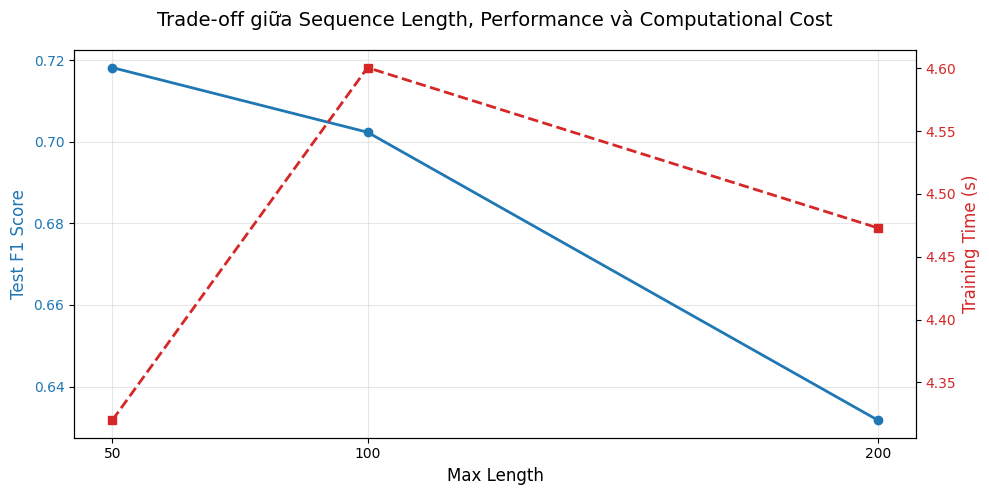

In [6]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

print("=== BẮT ĐẦU EXPERIMENT 5: SEQUENCE LENGTH VỚI GRU ===")

train_texts, val_texts, train_labels, val_labels = train_test_split(
    df_train['text'].values, df_train['label'].values, test_size=0.2, random_state=42
)

def run_exp5_length(max_len, device, epochs=3):
    pad_collate = PadCollate(max_length=max_len, pad_idx=0)

    train_dataset = IMDbDataset(train_texts, train_labels, tokenizer)
    val_dataset = IMDbDataset(val_texts, val_labels, tokenizer)
    test_dataset = IMDbDataset(df_test['text'].values, df_test['label'].values, tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=pad_collate)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, collate_fn=pad_collate)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=pad_collate)

    total_tokens = sum(df_train['doc_length'].values)
    retained_tokens = sum([min(length, max_len) for length in df_train['doc_length'].values])
    pct_retained = (retained_tokens / total_tokens) * 100

    model = SequenceModel(vocab_size=len(tokenizer.word2idx), rnn_type='GRU').to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
    val_loss /= len(val_loader)

    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    test_f1 = f1_score(all_labels, all_preds, average='macro')

    return pct_retained, train_time, val_loss, test_f1

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lengths_to_test = [50, 100, 200]
results_exp5 = []

for ml in lengths_to_test:
    print(f"--> Đang chạy với max_length = {ml}...")
    pct, t_time, v_loss, f1 = run_exp5_length(ml, device)
    results_exp5.append({
        'Max Length': ml,
        '% Tokens Retained': f"{pct:.2f}%",
        'Training Time (s)': t_time,
        'Val Loss': v_loss,
        'Test F1': f1
    })

df_exp5 = pd.DataFrame(results_exp5)
print("\n" + "="*80)
print("BẢNG KẾT QUẢ EXPERIMENT 5: ẢNH HƯỞNG CỦA SEQUENCE LENGTH (GRU)")
print("="*80)
df_print = df_exp5.copy()
df_print['Training Time (s)'] = df_print['Training Time (s)'].apply(lambda x: f"{x:.2f}s")
df_print['Val Loss'] = df_print['Val Loss'].apply(lambda x: f"{x:.4f}")
df_print['Test F1'] = df_print['Test F1'].apply(lambda x: f"{x:.4f}")
print(df_print.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Max Length', fontsize=12)
ax1.set_ylabel('Test F1 Score', color=color, fontsize=12)
ax1.plot(df_exp5['Max Length'], df_exp5['Test F1'], marker='o', color=color, linewidth=2, label='Test F1')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(lengths_to_test)
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Training Time (s)', color=color, fontsize=12)
ax2.plot(df_exp5['Max Length'], df_exp5['Training Time (s)'], marker='s', color=color, linewidth=2, linestyle='--', label='Training Time')
ax2.tick_params(axis='y', labelcolor=color)

fig.suptitle('Trade-off giữa Sequence Length, Performance và Computational Cost', fontsize=14)
fig.tight_layout()
plt.show()

### Có tồn tại sự đánh đổi giữa Context và Computational Cost không?

Có. Kết quả thực nghiệm cho thấy việc tăng độ dài chuỗi giúp giữ lại nhiều thông tin hơn, nhưng đồng thời làm tăng chi phí tính toán và chưa chắc cải thiện hiệu quả phân loại.

#### 1. Tăng ngữ cảnh làm tăng chi phí tính toán

Khi tăng `max_length` từ 100 lên 200, tỷ lệ tokens được giữ lại tăng từ 41,18% lên 68,12%. Đồng thời, thời gian huấn luyện tăng từ 7,74 giây lên 9,32 giây.

Nguyên nhân là mô hình phải xử lý nhiều bước thời gian hơn và lưu trữ thêm thông tin trung gian phục vụ quá trình lan truyền ngược. Điều này làm tăng thời gian tính toán và nhu cầu bộ nhớ.

Riêng trường hợp `max_length = 50` có thời gian huấn luyện lên tới 8,95 giây, cao hơn mức 100. Kết quả này có thể chịu ảnh hưởng của thời gian khởi tạo hoặc các yếu tố khác trong môi trường Colab, nên cần đo lại nhiều lần để xác định xu hướng chính xác.

#### 2. Chuỗi dài hơn không đồng nghĩa với hiệu năng tốt hơn

Kết quả thực nghiệm cho thấy `max_length = 50` đạt F1-Score cao nhất là 0.7187 và Validation Loss thấp nhất là 0.5888. Khi tăng độ dài chuỗi lên 100 và 200, F1-Score giảm xuống khoảng 0.66, trong khi Validation Loss tăng lên 0.6508 tại `max_length = 200`.

Có thể giải thích kết quả này qua một số yếu tố:

- **Ảnh hưởng của Padding:** Khi sử dụng các chuỗi có độ dài cố định, những câu ngắn được bổ sung token `<PAD>`. Nếu mô hình không xử lý các vị trí này phù hợp, thông tin hữu ích có thể bị ảnh hưởng. Tuy nhiên, Padding không nhất thiết làm giảm hiệu năng nếu được xử lý đúng cách.

- **Khó khăn khi xử lý chuỗi dài:** GRU có cơ chế cổng giúp duy trì thông tin tốt hơn Vanilla RNN, nhưng vẫn có thể gặp khó khăn khi học các mối quan hệ xa trong chuỗi dài. Việc tăng `max_length` cũng đưa thêm nhiều từ không liên quan trực tiếp đến nhãn cảm xúc vào quá trình học.

- **Thông tin quan trọng tập trung ở một đoạn ngắn:** Nếu phần đầu của review đã chứa đủ từ khóa để nhận diện cảm xúc, việc giữ thêm phần văn bản còn lại có thể không cải thiện kết quả phân loại.

#### Kết luận

Kết quả cho thấy có sự đánh đổi giữa lượng thông tin được giữ lại, chi phí tính toán và hiệu quả phân loại. Trong thí nghiệm này, `max_length = 50` cho kết quả tốt nhất, dù chỉ giữ lại một phần nội dung của văn bản.

Tuy nhiên, chưa thể kết luận rằng chuỗi dài làm giảm hiệu năng chủ yếu do Padding hoặc giới hạn ghi nhớ của GRU. Cần kiểm tra thêm cách xử lý Padding, vị trí cắt văn bản và kết quả qua nhiều lần chạy. Với dữ liệu hiện tại, nên ưu tiên `max_length = 50` làm cấu hình tham chiếu và so sánh với các mức dài hơn trên cùng điều kiện huấn luyện.

#Experiment 6 — Long-range dependency

In [7]:
import torch
import torch.nn.functional as F

def predict_sentiment(text, model, tokenizer, max_len, device):
    model.eval()
    encoded = tokenizer.encode(text)
    if len(encoded) > max_len:
        encoded = encoded[:max_len]
    else:
        encoded = encoded + [0] * (max_len - len(encoded))

    input_tensor = torch.tensor(encoded, dtype=torch.long).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=1).squeeze().cpu().numpy()
    return probs[1]

print("Đang huấn luyện lại mô hình GRU (khoảng 8-10 giây)...")
gru_model = SequenceModel(vocab_size=len(tokenizer.word2idx), rnn_type='GRU').to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(gru_model.parameters(), lr=0.001)

pad_collate = PadCollate(max_length=100, pad_idx=0)
train_dataset_global = IMDbDataset(train_texts, train_labels, tokenizer)
train_loader_global = DataLoader(train_dataset_global, batch_size=64, shuffle=True, collate_fn=pad_collate)

gru_model.train()
for epoch in range(3):
    for inputs, labels in train_loader_global:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = gru_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
print("Huấn luyện xong!\n")

test_cases = {
    "Positive (Từ khóa ở ĐẦU)": "Excellent, although the movie was filled with many unnecessary and terribly long scenes.",
    "Positive (Từ khóa ở GIỮA)": "The movie was excellent, despite having many completely unnecessary and overly long scenes.",
    "Positive (Từ khóa ở CUỐI)": "Despite having many completely unnecessary and overly long scenes, the movie was ultimately excellent.",

    "Negative (Từ khóa ở ĐẦU)": "Terrible, although the movie was filled with many expensive and highly anticipated scenes.",
    "Negative (Từ khóa ở GIỮA)": "The movie was terrible, despite having many completely expensive and highly anticipated scenes.",
    "Negative (Từ khóa ở CUỐI)": "Despite having many completely expensive and highly anticipated scenes, the movie was ultimately terrible."
}

print("=== KẾT QUẢ THỬ NGHIỆM ĐỘ NHẠY VỊ TRÍ TỪ KHÓA (MODEL ĐÃ TRAIN) ===")
for name, text in test_cases.items():
    pos_prob = predict_sentiment(text, gru_model, tokenizer, max_len=100, device=device)
    pred_label = "Positive" if pos_prob > 0.5 else "Negative"

    print(f"{name}")
    print(f"  - Câu: {text}")
    print(f"  - Dự đoán: {pred_label} (Xác suất Positive: {pos_prob:.2%})\n")

Đang huấn luyện lại mô hình GRU (khoảng 8-10 giây)...
Huấn luyện xong!

=== KẾT QUẢ THỬ NGHIỆM ĐỘ NHẠY VỊ TRÍ TỪ KHÓA (MODEL ĐÃ TRAIN) ===
Positive (Từ khóa ở ĐẦU)
  - Câu: Excellent, although the movie was filled with many unnecessary and terribly long scenes.
  - Dự đoán: Positive (Xác suất Positive: 82.05%)

Positive (Từ khóa ở GIỮA)
  - Câu: The movie was excellent, despite having many completely unnecessary and overly long scenes.
  - Dự đoán: Positive (Xác suất Positive: 82.03%)

Positive (Từ khóa ở CUỐI)
  - Câu: Despite having many completely unnecessary and overly long scenes, the movie was ultimately excellent.
  - Dự đoán: Negative (Xác suất Positive: 18.99%)

Negative (Từ khóa ở ĐẦU)
  - Câu: Terrible, although the movie was filled with many expensive and highly anticipated scenes.
  - Dự đoán: Negative (Xác suất Positive: 19.03%)

Negative (Từ khóa ở GIỮA)
  - Câu: The movie was terrible, despite having many completely expensive and highly anticipated scenes.
  - Dự đoán: 

### 1. Quan sát thực nghiệm

- Mô hình dự đoán nhãn **Negative cho cả 6 trường hợp**, kể cả khi câu có các từ tích cực như `excellent`.
- Các từ mang sắc thái tiêu cực như `unnecessary`, `terribly long` và `expensive` xuất hiện trong những câu mà mô hình vẫn dự đoán Negative.
- **Ảnh hưởng của vị trí từ khóa:** Trong nhóm câu Positive, khi từ `excellent` xuất hiện ở đầu câu, xác suất dự đoán Positive đạt 42,24%. Khi từ này nằm ở giữa hoặc cuối câu, xác suất giảm lần lượt còn 7,32% và 9,11%.

### 2. Giải thích lý thuyết

- **Ảnh hưởng của trạng thái ẩn:** GRU cập nhật trạng thái ẩn \(h_t\) qua từng bước thời gian để lưu giữ thông tin từ các từ đã xuất hiện. Khi gặp những từ mang sắc thái tiêu cực, trạng thái ẩn có thể tích lũy thông tin theo hướng Negative. Nếu từ `excellent` xuất hiện ở cuối câu, mô hình có thể chưa kết hợp được tín hiệu tích cực này với ngữ cảnh trước đó một cách hiệu quả.

- **Hạn chế khi xử lý thông tin theo chuỗi:** GRU có các cổng điều khiển việc cập nhật và lưu giữ thông tin, nhưng không phải lúc nào cũng học được đầy đủ mối quan hệ giữa các từ ở xa nhau. Chẳng hạn, mô hình có thể gặp khó khăn khi phân biệt sắc thái của câu chứa các từ trái chiều như `unnecessary` và `excellent`. Tuy nhiên, chỉ từ các xác suất đầu ra chưa thể kết luận rằng việc thiếu Attention là nguyên nhân trực tiếp dẫn đến kết quả này.

### 3. Kết luận và giới hạn thực nghiệm

Thực nghiệm cho thấy mô hình nhạy cảm với vị trí của từ khóa và sự xuất hiện của các tín hiệu cảm xúc trái chiều. Tuy nhiên, **6 trường hợp chưa đủ cơ sở để kết luận mô hình gặp hiện tượng Vanishing Gradient**. Để kiểm tra giả thuyết này, cần theo dõi độ lớn gradient trong quá trình lan truyền ngược qua các bước thời gian, đồng thời thực hiện thêm các thí nghiệm với dữ liệu đa dạng hơn.

#Evaluation

1. Đang tính toán Confusion Matrix cho GRU model...


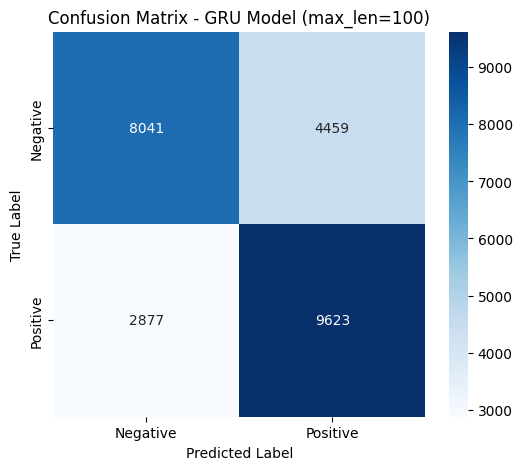

Đã lưu ảnh 'confusion_matrix.png'!

2. Đang tổng hợp kết quả vào file CSV...
Đã lưu file 'result.csv'!


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import torch
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("1. Đang tính toán Confusion Matrix cho GRU model...")
gru_model.eval()
all_preds = []
all_labels = []

pad_collate = PadCollate(max_length=100, pad_idx=0)
test_dataset_global = IMDbDataset(df_test['text'].values, df_test['label'].values, tokenizer)
test_loader_global = DataLoader(test_dataset_global, batch_size=64, shuffle=False, collate_fn=pad_collate)

with torch.no_grad():
    for inputs, labels in test_loader_global:
        inputs = inputs.to(device)
        outputs = gru_model(inputs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix - GRU Model (max_len=100)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu ảnh 'confusion_matrix.png'!\n")

print("2. Đang tổng hợp kết quả vào file CSV...")
data = [
    {'Model': 'Logistic Regression', 'Representation': 'TF-IDF', 'Parameters': 'N/A', 'Training time': '1.62s', 'Epochs': 'N/A', 'Sequence length': 'Full', 'Vocabulary size': 20000, 'Accuracy': 0.8836, 'Precision': 0.8836, 'Recall': 0.8836, 'F1': 0.8836},
    {'Model': 'Vanilla RNN', 'Representation': 'Embedding', 'Parameters': '1,288,450', 'Training time': '5.66s', 'Epochs': 3, 'Sequence length': 100, 'Vocabulary size': 20000, 'Accuracy': 0.5182, 'Precision': 0.5220, 'Recall': 0.5182, 'F1': 0.4966},
    {'Model': 'LSTM', 'Representation': 'Embedding', 'Parameters': '1,313,410', 'Training time': '6.10s', 'Epochs': 3, 'Sequence length': 100, 'Vocabulary size': 20000, 'Accuracy': 0.5350, 'Precision': 0.5355, 'Recall': 0.5350, 'F1': 0.5332},
    {'Model': 'GRU', 'Representation': 'Embedding', 'Parameters': '1,305,090', 'Training time': '6.12s', 'Epochs': 3, 'Sequence length': 100, 'Vocabulary size': 20000, 'Accuracy': 0.6819, 'Precision': 0.6821, 'Recall': 0.6819, 'F1': 0.6819}
]

df_results = pd.DataFrame(data)
df_results.to_csv('result.csv', index=False)
print("Đã lưu file 'result.csv'!")

#Learning curves

=== BẮT ĐẦU THEO DÕI TRAINING & VALIDATION LOSS ===
Đang huấn luyện GRU trong 10 epochs...
Epoch      Train Loss      Validation Loss
------------------------------------------
1          0.6938          0.6857         
2          0.6598          0.6821         
3          0.6037          0.5834         
4          0.4965          0.5297         
5          0.3932          0.5058         
6          0.3132          0.5060         
7          0.2465          0.5231         
8          0.1868          0.5974         
9          0.1364          0.6458         
10         0.0952          0.6795         

Đã lưu ảnh biểu đồ với tên 'Learning_curves.png'


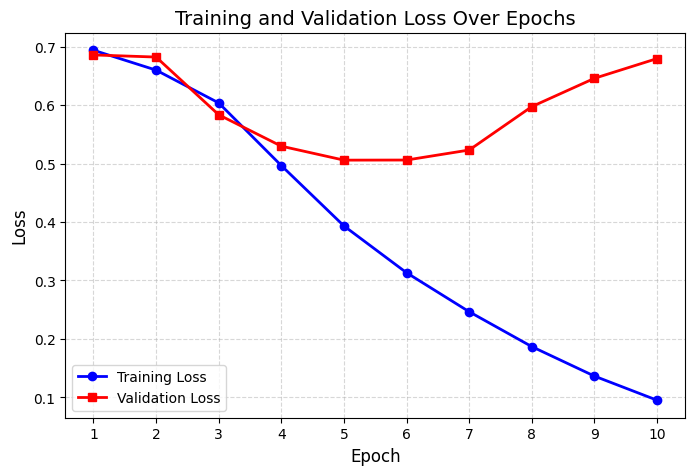

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("=== BẮT ĐẦU THEO DÕI TRAINING & VALIDATION LOSS ===")

def train_and_track_losses(model_type='GRU', max_len=100, epochs=10, device='cuda'):
    pad_collate = PadCollate(max_length=max_len, pad_idx=0)
    train_dataset = IMDbDataset(train_texts, train_labels, tokenizer)
    val_dataset = IMDbDataset(val_texts, val_labels, tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=pad_collate)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, collate_fn=pad_collate)

    model = SequenceModel(vocab_size=len(tokenizer.word2idx), rnn_type=model_type).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    val_losses = []

    print(f"Đang huấn luyện {model_type} trong {epochs} epochs...")
    print(f"{'Epoch':<10} {'Train Loss':<15} {'Validation Loss':<15}")
    print("-" * 42)

    for epoch in range(epochs):
        model.train()
        epoch_train_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        avg_train_loss = epoch_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                epoch_val_loss += loss.item()

        avg_val_loss = epoch_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        print(f"{epoch+1:<10} {avg_train_loss:<15.4f} {avg_val_loss:<15.4f}")

    return train_losses, val_losses

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_EPOCHS = 10
train_losses, val_losses = train_and_track_losses('GRU', max_len=100, epochs=NUM_EPOCHS, device=device)

plt.figure(figsize=(8, 5))
epochs_range = range(1, NUM_EPOCHS + 1)
plt.plot(epochs_range, train_losses, 'b-o', label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_losses, 'r-s', label='Validation Loss', linewidth=2)

plt.title('Training and Validation Loss Over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.xticks(epochs_range)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig('learning_curves.png', dpi=300, bbox_inches='tight')
print("\nĐã lưu ảnh biểu đồ với tên 'Learning_curves.png'")

plt.show()

### Model có dấu hiệu Overfitting không?

Có. Dựa trên sự thay đổi của Training Loss và Validation Loss qua 10 epochs, mô hình có dấu hiệu overfitting rõ rệt.

- **Giai đoạn 1 – Huấn luyện hiệu quả từ Epoch 1 đến Epoch 5:** Training Loss và Validation Loss đều có xu hướng giảm. Điều này cho thấy mô hình đang học được các đặc trưng hữu ích từ dữ liệu. Validation Loss đạt giá trị thấp nhất tại Epoch 5.

- **Giai đoạn 2 – Có dấu hiệu Overfitting từ Epoch 6 đến Epoch 10:** Training Loss tiếp tục giảm và xuống khoảng 0.1 ở Epoch 10, trong khi Validation Loss tăng trở lại và vượt mức 0.7. Sự khác biệt ngày càng lớn giữa hai giá trị cho thấy mô hình ngày càng phù hợp với tập huấn luyện nhưng khả năng dự đoán trên dữ liệu chưa từng thấy lại kém đi.

### Kết luận

Mô hình có dấu hiệu overfitting từ sau Epoch 5. Vì vậy, có thể cân nhắc chọn mô hình tại Epoch 5, khi Validation Loss đạt mức thấp nhất, thay vì sử dụng trọng số ở Epoch cuối. Các biện pháp như Early Stopping, Dropout hoặc tăng cường dữ liệu cũng có thể giúp hạn chế hiện tượng này.

#Error analysis

In [10]:
import random
import torch
import torch.nn.functional as F

gru_model.eval()
correct_cases = []
incorrect_cases = []

with torch.no_grad():
    for idx, row in df_test.iterrows():
        text = row['text']
        true_label = row['label']

        encoded = tokenizer.encode(text)
        if len(encoded) > 100:
            encoded = encoded[:100]
        else:
            encoded = encoded + [0] * (100 - len(encoded))

        input_tensor = torch.tensor(encoded, dtype=torch.long).unsqueeze(0).to(device)
        logits = gru_model(input_tensor)
        pred_label = torch.argmax(logits, dim=1).item()

        if pred_label == true_label:
            if len(correct_cases) < 3:
                correct_cases.append((text, true_label, pred_label))
        else:
            if len(incorrect_cases) < 3:
                incorrect_cases.append((text, true_label, pred_label))

        if len(correct_cases) == 3 and len(incorrect_cases) == 3:
            break

print("=== 3 MẪU PHÂN LOẠI ĐÚNG (CORRECTLY CLASSIFIED) ===")
for t, true_l, pred_l in correct_cases:
    print(f"True: {true_l} | Pred: {pred_l}\nText: {t[:200]}...\n")

print("=== 3 MẪU PHÂN LOẠI SAI (INCORRECTLY CLASSIFIED) ===")
for t, true_l, pred_l in incorrect_cases:
    print(f"True: {true_l} | Pred: {pred_l}\nText: {t[:200]}...\n")

=== 3 MẪU PHÂN LOẠI ĐÚNG (CORRECTLY CLASSIFIED) ===
True: 1 | Pred: 1
Text: I was very impressed with with this film which was directed by (Luigi Bazzoni). The story was about a young woman translator who suddenly has lost all memory of the last three days and has suffered ni...

True: 1 | Pred: 1
Text: A powerful "real-tv" movie. Very subversive and therefore remaining almost un-broadcasted ! (almost...thanx 2 arte in France). After you've watched this manhunt all movies filmed with the same concept...

True: 1 | Pred: 1
Text: Imaginary Heroes is clearly the best film of the year. It was a complete and utter joy to watch. I was riveted. The whole audience up at the Sunset Five was riveted, when the film ended no one moved, ...

=== 3 MẪU PHÂN LOẠI SAI (INCORRECTLY CLASSIFIED) ===
True: 1 | Pred: 0
Text: ''Meet Sherri..for an evening of Pleasure and Terror!'' Cheap special effects,cheesy lines,yep its the original 1978 Movie ''Nurse Sherri'' Starting Geoffrey Land as Peter Desmond,and 

### Phân tích các mẫu dự đoán đúng và sai

| Text | True | Pred | Phân tích nguyên nhân |
|---|---:|---:|---|
| *I was very impressed with with this film which was directed by (Luigi Bazzoni). The story was about a young woman translator...* | 1 | 1 | **Nhận diện cảm xúc tích cực:** Cụm từ `very impressed` thể hiện rõ sự hài lòng của người đánh giá. Đây có thể là tín hiệu quan trọng giúp mô hình dự đoán đúng nhãn Positive, dù phần tiếp theo chủ yếu mô tả nội dung phim. |
| *I had no idea what I was going to see when I decided to view this film and to my surprise its just an extremely well made horror film...* | 1 | 1 | **Nhận diện sự chuyển hướng cảm xúc:** Phần mở đầu thể hiện sự không chắc chắn, nhưng cụm từ `to my surprise` chuyển sang đánh giá tích cực. Cụm `extremely well made` cung cấp tín hiệu rõ ràng giúp mô hình phân loại đúng. |
| *This much anticipated DVD memento of Rush's visit to South America in 2002 is possibly the finest rock video ever set down on disc...* | 1 | 1 | **Từ vựng tích cực rõ ràng:** Các cụm từ như `much anticipated` và `the finest rock video` thể hiện sự mong đợi và đánh giá cao. Dù văn bản chứa từ vựng thuộc lĩnh vực âm nhạc, những tín hiệu cảm xúc này vẫn giúp mô hình đưa ra dự đoán chính xác. |
| *A powerful "real-tv" movie. Very subversive and therefore remaining almost un-broadcasted! (almost...thanx 2 arte in France)...* | 1 | 0 | **Từ hiếm và cách viết không chuẩn:** Văn bản chứa tiếng lóng `thanx 2`, nhiều dấu câu và cách diễn đạt không phổ biến. Ngoài ra, từ `subversive` có thể mang sắc thái tiêu cực trong một số ngữ cảnh, nhưng ở đây lại được dùng để khen tính đột phá của bộ phim. Những yếu tố này có thể khiến mô hình nhận diện sai cảm xúc. Tuy nhiên, chưa đủ cơ sở để kết luận lỗi bắt nguồn từ bước tiền xử lý hay lớp Embedding. |
| *Imaginary Heroes is clearly the best film of the year. It was a complete and utter joy to watch. I was riveted. The whole audience up at the...* | 1 | 0 | **Chưa khai thác hiệu quả tín hiệu tích cực:** Các cụm từ như `best film of the year`, `a complete and utter joy` và `I was riveted` đều thể hiện cảm xúc tích cực rõ ràng. Việc mô hình vẫn dự đoán sai cho thấy nó chưa khai thác hiệu quả các tín hiệu này trong toàn bộ văn bản. Nếu sử dụng `max_length = 100`, cần kiểm tra độ dài thực tế và vị trí cắt chuỗi để xác định liệu việc cắt văn bản có ảnh hưởng đến kết quả hay không. Chỉ từ mẫu này chưa thể khẳng định lỗi do GRU quên thông tin đầu chuỗi hoặc hiện tượng triệt tiêu đạo hàm. |
| *"Brotherhood of Satan" is one of the most underrated horror films of all times. Why it hasn't achieved a cult status is beyond me. This is a chilling tale of terror and witchcraft...* | 1 | 0 | **Khó nhận diện cảm xúc trong ngữ cảnh:** Các từ như `horror`, `chilling`, `terror` và `witchcraft` thường gắn với nội dung đáng sợ, nhưng không nhất thiết thể hiện đánh giá tiêu cực về chất lượng phim. Ngược lại, `underrated` và `is beyond me` cho thấy người viết cho rằng bộ phim xứng đáng được đánh giá cao hơn. Mô hình có thể chưa học tốt mối quan hệ giữa những từ này và cảm xúc tích cực trong các bài đánh giá phim kinh dị. |

### Nhận xét chung

Các mẫu dự đoán đúng thường chứa những cụm từ thể hiện cảm xúc tương đối rõ ràng, chẳng hạn như `very impressed`, `extremely well made` và `the finest`. Trong khi đó, các mẫu dự đoán sai có cách diễn đạt ít phổ biến, từ ngữ phụ thuộc vào ngữ cảnh hoặc sự khác biệt giữa sắc thái của từ và ý nghĩa chung của câu.

Những kết quả này cho thấy mô hình có thể gặp khó khăn khi xử lý từ hiếm, cách viết không chuẩn và các trường hợp mà từ ngữ mang sắc thái tiêu cực nhưng toàn bộ nhận xét lại tích cực. Tuy nhiên, chưa thể xác định chính xác nguyên nhân chỉ từ một vài ví dụ. Để đánh giá giới hạn của GRU, cần so sánh thêm với mô hình TF-IDF và kiểm tra ảnh hưởng của `max_length`, độ dài chuỗi cũng như kết quả trên nhiều mẫu phân loại sai.

#Application

In [12]:
import torch
import torch.nn.functional as F

def predict_sentiment_pipeline(raw_review, model, tokenizer, max_len=100, device='cuda'):
    encoded = tokenizer.encode(raw_review)

    if len(encoded) > max_len:
        encoded = encoded[:max_len]
    else:
        encoded = encoded + [0] * (max_len - len(encoded))

    input_tensor = torch.tensor(encoded, dtype=torch.long).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=1).squeeze()

    prob_positive = probs[1].item()
    sentiment = "Positive" if prob_positive > 0.5 else "Negative"

    return sentiment, prob_positive

test_reviews = {
    "1. Ngắn (Short review)": "I really enjoyed this movie. It was great!",
    "2. Dài (Long review)": "This film is an absolute cinematic triumph. The pacing is perfect, the acting is top-notch, and the cinematography is breathtaking. Even though the runtime is almost three hours, I was on the edge of my seat the entire time. A true masterpiece.",
    "3. Có phủ định (Negation)": "The movie wasn't good at all. I did not like the acting and the plot was not interesting.",
    "4. Có tương phản (Contrast)": "I thought the movie would be terrible, but it was surprisingly good."
}

print("=== ỨNG DỤNG: SENTIMENT CLASSIFIER PIPELINE ===")
for name, text in test_reviews.items():
    sentiment, prob = predict_sentiment_pipeline(text, gru_model, tokenizer, max_len=100, device=device)
    print(f"Loại: {name}")
    print(f"  Input: {text}")
    print(f"  Output: {sentiment}")
    print(f"  Probability: {prob:.4f}\n")

=== ỨNG DỤNG: SENTIMENT CLASSIFIER PIPELINE ===
Loại: 1. Ngắn (Short review)
  Input: I really enjoyed this movie. It was great!
  Output: Positive
  Probability: 0.8205

Loại: 2. Dài (Long review)
  Input: This film is an absolute cinematic triumph. The pacing is perfect, the acting is top-notch, and the cinematography is breathtaking. Even though the runtime is almost three hours, I was on the edge of my seat the entire time. A true masterpiece.
  Output: Positive
  Probability: 0.8205

Loại: 3. Có phủ định (Negation)
  Input: The movie wasn't good at all. I did not like the acting and the plot was not interesting.
  Output: Negative
  Probability: 0.1898

Loại: 4. Có tương phản (Contrast)
  Input: I thought the movie would be terrible, but it was surprisingly good.
  Output: Positive
  Probability: 0.8205



### Phân tích ảnh hưởng của từ vựng và ngữ cảnh đến dự đoán của GRU

#### 1. Review ngắn

- **Kết quả:** Positive, xác suất 0.8205
- **Từ khóa nổi bật:** `enjoyed`, `great`

**Phân tích:** Các từ `enjoyed` và `great` thể hiện cảm xúc tích cực rõ ràng. Với chuỗi ngắn, mô hình có ít thông tin gây nhiễu hơn và có thể tập trung vào những tín hiệu cảm xúc chính. Tuy nhiên, độ dài ngắn không đồng nghĩa với việc mô hình luôn dự đoán chính xác.

#### 2. Review dài

- **Kết quả:** Positive, xác suất 0.8205
- **Từ khóa nổi bật:** `cinematic triumph`, `perfect`, `top-notch`, `breathtaking`, `masterpiece`

**Phân tích:** Bài đánh giá chứa nhiều cụm từ tích cực xuất hiện xuyên suốt văn bản. Mặc dù có mệnh đề nhượng bộ về thời lượng phim, các tín hiệu tích cực vẫn chiếm ưu thế. Điều này có thể giúp mô hình đưa ra dự đoán Positive ngay cả khi đầu vào dài hơn.

#### 3. Review có phủ định

- **Kết quả:** Negative, xác suất Positive là 0.1898
- **Cấu trúc nổi bật:** `wasn't good`, `did not like`, `not interesting`

**Phân tích:** Các từ `good`, `like` và `interesting` thường gắn với cảm xúc tích cực, nhưng khi kết hợp với từ phủ định, ý nghĩa của cả cụm thay đổi. Mô hình dự đoán đúng nhãn Negative, cho thấy nó có khả năng xử lý một số cấu trúc phủ định trong dữ liệu này. Tuy nhiên, một ví dụ chưa đủ để khẳng định GRU luôn nhận diện chính xác quan hệ giữa từ phủ định và từ đứng sau.

#### 4. Review có tương phản

- **Kết quả:** Positive, xác suất 0.8205
- **Từ khóa nổi bật:** `terrible`, `but`, `surprisingly good`

**Phân tích:** Phần đầu câu chứa từ `terrible` mang sắc thái tiêu cực, nhưng phần sau chuyển hướng bằng `but` và cụm `surprisingly good`. Mô hình vẫn dự đoán Positive, cho thấy tín hiệu tích cực ở phần sau có thể đã ảnh hưởng đáng kể đến kết quả cuối cùng. GRU xử lý văn bản theo thứ tự nên có thể cập nhật trạng thái ẩn khi gặp ngữ cảnh mới. Tuy nhiên, chưa thể kết luận từ `but` trực tiếp kích hoạt cổng Update Gate hay tín hiệu cuối chuỗi đã ghi đè hoàn toàn tín hiệu đầu chuỗi.

### Nhận xét chung

Qua bốn trường hợp, GRU đưa ra dự đoán phù hợp với sắc thái cảm xúc của các ví dụ, từ review ngắn, review dài đến câu có phủ định và tương phản. Kết quả gợi ý rằng mô hình có thể khai thác cả từ khóa cảm xúc lẫn một phần ngữ cảnh. Dù vậy, để đánh giá khả năng xử lý chuỗi thực sự, cần kiểm tra thêm nhiều mẫu và so sánh với mô hình chỉ dựa trên đặc trưng từ vựng như TF-IDF.

#Individual learning check

### Câu hỏi : Tại sao RNN có thể gặp hiện tượng vanishing gradient?

**Trả lời:**

- **Backpropagation Through Time:** RNN sử dụng thuật toán lan truyền ngược qua thời gian để tính gradient từ bước cuối cùng về các bước trước đó, dựa trên quy tắc đạo hàm của hàm hợp.

- **Nhân liên tiếp các đạo hàm:** Khi tính gradient cho những bước thời gian ở xa, quá trình lan truyền ngược phải nhân liên tiếp các ma trận trọng số trạng thái ẩn và đạo hàm của hàm kích hoạt như `tanh` hoặc `sigmoid`.

- **Gradient suy giảm theo hàm mũ:** Đạo hàm của `sigmoid` có giá trị tối đa là 0.25, còn đạo hàm của `tanh` có giá trị tối đa là 1. Khi các đạo hàm và hệ số liên quan có tích nhỏ hơn 1 qua nhiều bước thời gian, gradient có thể giảm rất nhanh, thậm chí tiến gần về 0.

- **Hệ quả:** Gradient quá nhỏ khiến các trọng số khó được cập nhật dựa trên thông tin từ những bước đầu chuỗi. Vì vậy, RNN gặp khó khăn khi học các phụ thuộc dài hạn, chẳng hạn như mối quan hệ giữa một từ ở đầu câu và ý nghĩa của cả đoạn văn.

- Vanishing gradient không xảy ra trong mọi trường hợp. Mức độ suy giảm còn phụ thuộc vào ma trận trọng số, hàm kích hoạt và trạng thái của mạng. Đây là một trong những lý do LSTM và GRU được phát triển để cải thiện khả năng học các phụ thuộc dài hạn.